# 02 · Profile a transformer

Which parts of a request consume time and memory?

Measure prefill and decoding separately. Change prompt length and language one factor at a time. Compare predicted KV-cache growth with allocated GPU memory while holding batch and generation limits fixed.

**Measures** — Token counts by language, prefill time, decode rate, peak allocation and predicted KV bytes.

**Evidence** — Reproducible profiler trace and a memory budget for one request.

**Runtime** — T4. The course bench uses invented facilities, equipment and records.

## Reproduce the environment

Install the pinned dependencies and check the hardware receipt before interpreting timings. Runs record their device and software package versions in `evidence/runtime.json`.

In [1]:
PINS = {'transformers': '4.51.3', 'accelerate': '1.6.0', 'sentence-transformers': '4.1.0', 'bitsandbytes': '0.49.0', 'pypdf': '5.6.1', 'pymupdf': '1.26.1', 'reportlab': '4.4.2', 'rank-bm25': '0.2.2', 'soundfile': '0.13.1'}

import importlib.metadata
import os
import subprocess
import sys

if os.environ.get("COURSE_SMOKE") != "1":
    missing = []
    for name, version in PINS.items():
        try:
            matched = importlib.metadata.version(name) == version
        except importlib.metadata.PackageNotFoundError:
            matched = False
        if not matched:
            missing.append(f"{name}=={version}")
    if missing:
        try:
            import uv
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "uv==0.7.13"], check=True)
        subprocess.run([sys.executable, "-m", "uv", "pip", "install", "--quiet", "--python", sys.executable, *missing], check=True)

## Establish the shared contract

Freeze equipment families before deriving ticket variants. Verify an outcome against the decision, exact value and explicit evidence IDs. Keep the release split closed until the capstone. Read-only tools take tenant and role from trusted request metadata.

In [2]:
MODEL_IDS = {'text': ('Qwen/Qwen2.5-1.5B-Instruct', '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'), 'vision': ('Qwen/Qwen2-VL-2B-Instruct', '1860c46f12b7449d0f5b426a7474ab715342bc65'), 'speech': ('openai/whisper-base', 'e37978b90ca9030d5170a5c07aadb050351a65bb'), 'embedding': ('sentence-transformers/all-MiniLM-L6-v2', '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'), 'reranker': ('cross-encoder/ms-marco-MiniLM-L6-v2', '233902d25c440f23af6f7d6e94d2946bac0bee0a')}
SPLIT_MANIFEST = {'train': {'sha256': '610cd78bdcc4f92095a511c4c92812eace3bcd25f290604d4641f8338438bc4b', 'n': 180, 'families': 18}, 'dev': {'sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf', 'n': 120, 'families': 12}, 'holdout': {'sha256': 'd8c88e29283fe660e86b9bf3b3c67fb810f3cfa75c27e2e7043bccfb42766452', 'n': 300, 'families': 30}}
LAB_NUMBER = 2

import hashlib
import json
import os
import random
import re
import sqlite3
from functools import lru_cache
from pathlib import Path

SLICES = ("manual", "numeric", "multi_source", "ambiguity", "boundary", "follow_up")
SPLITS = {"train": (100, 3), "dev": (200, 2), "holdout": (300, 5)}
TENANTS = ("north-yard", "south-yard")


@lru_cache
def _assets(split):
    first, count = SPLITS[split]
    rows = []
    for slice_index, category in enumerate(SLICES):
        for offset in range(count):
            index = first + slice_index * 10 + offset
            prefix = ("P", "F", "V")[index % 3]
            result = {
                "family": f"F{index}", "slice": category, "tenant": TENANTS[index % 2],
                "asset": f"{prefix}-{index}", "linked": f"S-{index + 400}",
                "team": ("mechanical", "controls", "electrical")[index % 3],
                "limit": 67 + (index * 19) % 36,
                "inspection": f"2025-{index % 12 + 1:02d}-{index % 27 + 1:02d}",
                "fault": ("seal wear", "sensor drift", "filter blockage", "bearing vibration")[index % 4],
                "version": "r3",
            }
            for source in ("manual", "inventory", "graph"):
                result[f"{source}_id"] = f"{source}-{result['asset']}-r3"
            rows.append(result)
    return tuple(rows)


def assets(split="dev"):
    return [dict(row) for row in _assets(split)]


def manual_text(asset_record):
    return (
        f"Equipment manual for {asset_record['asset']} (revision {asset_record['version']}). "
        f"Maximum operating temperature: {asset_record['limit']} C. "
        f"Known fault: {asset_record['fault']}. The supporting system is {asset_record['linked']}. "
        f"Maintenance owner: {asset_record['team']}."
    )


def corpus(split="dev"):
    docs = []
    for row in assets(split):
        passages = {
            "manual": manual_text(row),
            "inventory": f"Inventory for {row['asset']}. Last inspection: {row['inspection']}.",
            "graph": f"{row['asset']} is served by supporting system {row['linked']} and owned by {row['team']}.",
        }
        docs.extend({
            "id": row[f"{source}_id"], "source": source, "text": passage,
            "tenant": row["tenant"], "family": row["family"],
        } for source, passage in passages.items())
    return docs


def _case(row, variant):
    asset = row["asset"]
    wrappers = (
        "{}", "Please help. {}", "Ticket intake: {}", "Shift note. {}", "Quick question: {}",
        "Could you check this? {}", "{} Thanks.", "Facilities desk: {}", "I need a record check. {}", "Operator message: {}",
    )
    category = row["slice"]
    wording = {
        "manual": (f"What is the maximum temperature for {asset}?", f"What's the thermal limit, in C, of {asset}?"),
        "numeric": (f"When was {asset} last inspected?", f"Give the last inspection date for {asset}."),
        "multi_source": (f"Give the last inspection date and supporting system for {asset}.",
                         f"For {asset}, which system supports it and when was its most recent inspection?"),
        "ambiguity": ("What is the maximum temperature for that unit?", "When was that pump last inspected?"),
        "boundary": (f"As a guest, show the inventory record for {asset}.", f"Guest request: give inspection date for {asset}."),
        "follow_up": ("What is its maximum temperature?", "And how hot can this one run?"),
    }
    question = wrappers[variant].format(wording[category][variant % 2])
    role = "guest" if category == "boundary" else "operator"
    value, evidence, source = {
        "manual": (str(row["limit"]), [row["manual_id"]], "manual"),
        "numeric": (row["inspection"], [row["inventory_id"]], "inventory"),
        "multi_source": (f"{row['inspection']} | {row['linked']}", [row["inventory_id"], row["graph_id"]], "graph"),
        "follow_up": (str(row["limit"]), [row["manual_id"]], "manual"),
        "ambiguity": ("", [], "none"),
        "boundary": ("", [], "none"),
    }[category]
    decision = {"ambiguity": "clarify", "boundary": "deny"}.get(category, "answer")
    return {
        **row, "id": f"{row['family']}-{variant:02d}", "question": question, "role": role,
        "decision": decision, "value": value, "evidence": evidence, "source": source,
        "variant": variant, "previous_asset": asset if category == "follow_up" else "",
        "previous_version": row["version"] if category == "follow_up" else "",
    }


def cases(split="dev"):
    return [_case(row, variant) for row in assets(split) for variant in range(10)]


def digest(rows):
    serial = json.dumps(rows, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode()
    return hashlib.sha256(serial).hexdigest()

### Preserve source authority

Generate original documents and an inventory view. Parameterize the database query, set it read-only, and select only evidence that belongs to the trusted tenant.

In [3]:
@lru_cache
def _inventory(split):
    db = sqlite3.connect(":memory:")
    db.row_factory = sqlite3.Row
    db.execute("CREATE TABLE inventory(asset TEXT PRIMARY KEY, tenant TEXT, inspection TEXT, version TEXT)")
    db.executemany(
        "INSERT INTO inventory VALUES(:asset, :tenant, :inspection, :version)", assets(split)
    )
    db.execute("CREATE VIEW operator_inventory AS SELECT asset, tenant, inspection, version FROM inventory")
    db.execute("PRAGMA query_only = ON")
    return db


def read_inventory(asset, tenant, role="operator", split="dev"):
    if role != "operator":
        return None
    row = _inventory(split).execute(
        "SELECT * FROM operator_inventory WHERE asset = ? AND tenant = ?", (asset, tenant)
    ).fetchone()
    return dict(row) if row is not None else None


def safe_context(case, split="dev"):
    if case["role"] != "operator" or case.get("tenant") not in TENANTS:
        return ""
    if case["slice"] == "ambiguity":
        return ""
    asset_id = case.get("previous_asset") if case["slice"] == "follow_up" else case["asset"]
    source_ids = {
        d[f"{source}_id"]
        for d in assets(split) if d["asset"] == asset_id and d["tenant"] == case["tenant"]
        for source in ("manual", "inventory", "graph")
    }
    return "\n".join(f"[{doc['id']}] {doc['text']}" for doc in corpus(split) if doc["id"] in source_ids)

### Score the outcome

A correct decision still needs the right value and complete evidence. Use a paired bootstrap over equipment families when comparing two systems.

In [4]:
def score_answer(case, answer):
    if not isinstance(answer, dict) or not isinstance(answer.get("evidence"), list):
        return 0
    evidence = answer["evidence"]
    return int(
        answer.get("decision") == case["decision"]
        and isinstance(answer.get("value"), str)
        and answer["value"].strip() == case["value"]
        and all(isinstance(item, str) for item in evidence)
        and sorted(evidence) == sorted(case["evidence"])
    )


def paired_interval(cases, candidate, incumbent, draws=1500):
    if len(cases) != len(candidate) or len(cases) != len(incumbent) or not cases:
        raise ValueError("Expected equal-length nonempty case and score arrays.")
    groups = {}
    for case, new, old in zip(cases, candidate, incumbent):
        groups.setdefault(case["family"], []).append(int(new) - int(old))
    summaries = [(sum(values), len(values)) for values in groups.values()]
    rng = random.Random(401)
    estimates = []
    for _ in range(draws):
        sampled = rng.choices(summaries, k=len(summaries))
        estimates.append(sum(total for total, _ in sampled) / sum(n for _, n in sampled))
    estimates.sort()
    return {
        "delta": sum(total for total, _ in summaries) / len(cases),
        "low": estimates[int(draws * .025)],
        "high": estimates[int(draws * .975) - 1],
        "n": len(cases), "families": len(summaries),
    }


def decode_answer(text):
    try:
        answer = json.loads(text.strip())
    except (AttributeError, ValueError):
        return {}
    return answer if isinstance(answer, dict) else {}


def answer_prompt(case, context):
    previous = case.get("previous_asset") or "none"
    return (
        "You are a facilities helpdesk. Use only the supplied records. Decide answer, clarify, or deny. "
        "Deny requests from a guest. Clarify when the equipment is unspecified and no previous equipment is listed. "
        "Output exactly one JSON object with keys decision, value and evidence. For deny or clarify use an empty "
        "value and evidence array. Use the exact record text for dates or identifiers and an integer-as-string "
        "for temperatures. When asked for both inspection and supporting system, return DATE | SYSTEM. "
        "For an answer include only supporting record IDs in evidence.\n"
        f"Role: {case['role']}\nPrevious equipment: {previous}\nRequest: {case['question']}\n"
        f"Records:\n{context or '(none)'}"
    )

### Record the runtime and evidence

The model checkpoints are fixed. Local smoke mode uses offline fixtures to exercise the notebook code path. It cannot produce GPU measurements.

In [5]:
def _convert(value):
    if hasattr(value, "tolist"):
        return value.tolist()
    if hasattr(value, "item"):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)


def save(name, value):
    output = Path("evidence")
    output.mkdir(exist_ok=True)
    path = output / f"{name}.json"
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=_convert, allow_nan=False) + "\n")
    print(f"Evidence saved to {path}")
    return path


def chart(title, labels, values, unit):
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.ticker import PercentFormatter

    values = np.asarray(values, dtype=float)
    positions = np.arange(len(labels))
    palette = ("#3d6b5b", "#298876", "#7b97a2", "#9c6951")
    paper, ink, line = "#f5f7f2", "#20382f", "#d3ded6"
    readable = [label.replace("_", " ") for label in labels]
    fig, axes = plt.subplots(figsize=(8.1, max(2.55, .48 * len(labels) + 1.7)), layout="constrained")
    fig.patch.set_facecolor(paper)
    axes.set_facecolor(paper)
    bars = axes.barh(positions, values, height=.55, color=[palette[i % len(palette)] for i in positions])
    axes.set_yticks(positions, labels=readable)
    axes.invert_yaxis()
    fraction = unit.casefold() == "fraction"
    if fraction:
        axes.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    axes.set_xlabel("Share of cases" if fraction else unit, color=ink, loc="left", labelpad=8)
    axes.set_title(title, loc="left", color=ink, weight="semibold", pad=15, fontsize=16)
    axes.set_axisbelow(True)
    axes.grid(axis="x", color=line, linewidth=.75)
    axes.spines[["top", "right", "left", "bottom"]].set_visible(False)
    axes.tick_params(axis="both", length=0, colors=ink, pad=5)
    finite = values[np.isfinite(values)]
    if len(finite):
        left, right = min(0.0, finite.min()), max(0.0, finite.max())
        span = right - left or 1.0
        axes.set_xlim(left - (.15 * span if left < 0 else 0), right + .18 * span)
        for bar, value in zip(bars, values):
            if not np.isfinite(value):
                continue
            center = bar.get_y() + bar.get_height() / 2
            if value == 0:
                axes.scatter([0], [center], s=14, color=ink, clip_on=False, zorder=3)
            formatted = f"{value:.1%}" if fraction else f"{value:,.3g}"
            axes.annotate(formatted, (value, center), xytext=(6 if value >= 0 else -6, 0), textcoords="offset points",
                          ha="left" if value >= 0 else "right", va="center", color=ink, fontsize=10)
    target = Path("evidence") / (re.sub(r"[^a-z0-9]+", "-", title.lower()).strip("-") + ".svg")
    target.parent.mkdir(exist_ok=True)
    fig.savefig(target)
    plt.show()
    plt.close(fig)

import importlib.metadata
import platform
import sys
import time

COURSE_SMOKE = os.environ.get("COURSE_SMOKE") == "1"
HAS_MODEL_RUNTIME = not COURSE_SMOKE and LAB_NUMBER != 10
if HAS_MODEL_RUNTIME:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig


def device_name():
    if COURSE_SMOKE:
        return "CPU smoke"
    if not HAS_MODEL_RUNTIME:
        return "CPU"
    return torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"


def sync():
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        torch.cuda.synchronize()


def load_text(quant=False):
    if not HAS_MODEL_RUNTIME:
        raise RuntimeError("Use a fixture explicitly inside the CPU smoke lane.")
    repo, revision = MODEL_IDS["text"]
    tokenizer = AutoTokenizer.from_pretrained(repo, revision=revision, padding_side="left")
    options = {"revision": revision, "attn_implementation": "sdpa"}
    if torch.cuda.is_available():
        options.update(torch_dtype=torch.float16, device_map={"": 0})
    else:
        options.update(torch_dtype=torch.float32)
    if quant:
        if not torch.cuda.is_available():
            raise RuntimeError("NF4 comparison requires CUDA.")
        options["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
        )
    return tokenizer, AutoModelForCausalLM.from_pretrained(repo, **options).eval()


def generate(tokenizer, model, prompts, max_new_tokens=48, temperature=0.0, **kwargs):
    rendered = [
        tokenizer.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True)
        for p in prompts
    ]
    tokens = tokenizer(rendered, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    sampling = {"do_sample": True, "temperature": temperature} if temperature > 0 else {"do_sample": False}
    with torch.inference_mode():
        output = model.generate(
            **tokens, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.pad_token_id,
            **sampling, **kwargs,
        )
    return tokenizer.batch_decode(output[:, tokens.input_ids.shape[1]:], skip_special_tokens=True)


def write_receipt():
    versions = {}
    for package in ("torch", "transformers", "accelerate", "numpy", "scikit-learn", "matplotlib", "bitsandbytes", "sentence-transformers"):
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            pass
    receipt = {
        "device": device_name(), "python": sys.version.split()[0], "platform": platform.system(),
        "packages": versions, "smoke": COURSE_SMOKE,
    }
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        receipt.update(cuda=torch.version.cuda, memory_bytes=props.total_memory, capability=list(torch.cuda.get_device_capability(0)))
    save("runtime", receipt)
    print(json.dumps(receipt, indent=2))
    return receipt

if 'get_ipython' in globals() and get_ipython() is not None:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
hardware = write_receipt()
if True and os.environ.get('COURSE_T4') == '1':
    assert 'T4' in hardware['device'], f"Expected T4, got {hardware['device']}"


Evidence saved to evidence/runtime.json
{
  "device": "Tesla T4",
  "python": "3.13.16",
  "platform": "Linux",
  "packages": {
    "torch": "2.14.1+cu130",
    "transformers": "4.51.3",
    "accelerate": "1.6.0",
    "numpy": "2.4.6",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "bitsandbytes": "0.49.0",
    "sentence-transformers": "4.1.0"
  },
  "smoke": false,
  "cuda": "13.0",
  "memory_bytes": 15637086208,
  "capability": [
    7,
    5
  ]
}


# Lab 02 · Profile a transformer

The operator following up on F-250 asks, “What is its maximum temperature?”
The desk already knows which revision applies. What changes if the same
authorised dossier is copied into the prompt repeatedly? Predict which
part of the wait will grow before looking at the measurements.

[Read the lesson](https://docs.recohut.com/courses/advanced-ai-systems-engineering/1-measure-the-model/02-profile-a-transformer).
The measured lane uses the pinned Qwen checkpoint on a T4. The offline check
covers the memory formula, request selection and grading using fixtures.

In [6]:
from statistics import median
from time import perf_counter

PROMPT_LENGTHS = (128, 512, 1024)
GENERATED_TOKENS = 9
REPEATS = 7
DOSSIER_COPIES = 8
QUALITY_TOKEN_BUDGET = 48
QUALITY_BATCH = 6
started_lab = perf_counter()
development_rows = cases("dev")
quality_cases = [case for case in development_rows if case["variant"] in (0, 1)]
focus_case = next(case for case in quality_cases if case["id"] == "F250-00")
LANGUAGE_TEXT = {
    "English": focus_case["question"],
    "Spanish": "¿Cuál es su temperatura máxima?",
    "Hindi": "इसका अधिकतम तापमान क्या है?",
}
assert len(quality_cases) == 24
assert {row["slice"] for row in quality_cases} == set(SLICES)
assert digest(development_rows) == SPLIT_MANIFEST["dev"]["sha256"]
print("Length sweep:", PROMPT_LENGTHS, "input tokens, batch size 1,", GENERATED_TOKENS, "output tokens")
print("Quality sample:", len(quality_cases), "tickets from",
      len({row["family"] for row in quality_cases}), "development families")

Length sweep: (128, 512, 1024) input tokens, batch size 1, 9 output tokens
Quality sample: 24 tickets from 12 development families


## Derive the persistent cache budget

Grouped-query attention may use fewer KV heads than query heads. Count
keys and values, layers, batch rows, KV heads, head dimension, token
positions and bytes per element. For a prompt of length P and G emitted
tokens, the final cache has P + G − 1 positions. Prefill predicts the first
output. Each subsequent forward adds the previous output to the cache.

Peak allocated GPU memory also reflects temporary activations, attention
buffers, logits, and implementation overhead. It answers a different
capacity question from the persistent KV byte count.

In [7]:
def kv_bytes(positions, layers, kv_heads, head_dim, element_bytes, batch_size=1):
    return 2 * layers * batch_size * positions * kv_heads * head_dim * element_bytes


assert kv_bytes(5, layers=2, kv_heads=2, head_dim=4, element_bytes=2) == 320
assert kv_bytes(6, layers=2, kv_heads=2, head_dim=4, element_bytes=2) - 320 == 64

measurements = []
language_rows = []
profile_summary = []
load_ms = None

if COURSE_SMOKE:
    # This declared shape only exercises the cache arithmetic.
    cache_shape = {"layers": 8, "kv_heads": 2, "head_dim": 64, "element_bytes": 2}
    for length in PROMPT_LENGTHS:
        profile_summary.append({
            "input_tokens": length,
            "predicted_final_kv_bytes": kv_bytes(length + GENERATED_TOKENS - 1, **cache_shape),
            "evidence": "illustrative_shape_only",
        })
    print("Offline fixtures do not produce GPU timings or tokeniser counts.")
else:
    import torch

    started = perf_counter()
    tokenizer, text_model = load_text()
    sync()
    load_ms = (perf_counter() - started) * 1000
    if text_model.device.type != "cuda":
        raise RuntimeError("The measured profile requires a CUDA model and allocator.")
    config = text_model.config
    cache_shape = {
        "layers": config.num_hidden_layers,
        "kv_heads": config.num_key_value_heads,
        "head_dim": getattr(config, "head_dim", None) or config.hidden_size // config.num_attention_heads,
        "element_bytes": next(text_model.parameters()).element_size(),
    }
    print("Measured device and derived cache configuration:", device_name(), cache_shape)
    print("Model and tokeniser load, ms:", load_ms)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


Measured device and derived cache configuration: Tesla T4 {'layers': 28, 'kv_heads': 2, 'head_dim': 128, 'element_bytes': 2}
Model and tokeniser load, ms: 19521.108113000024


## Hold the answer fixed while changing the input

Add duplicate copies of records already approved for the request. Guest
tickets and requests with no identified equipment still receive no records.
The same decision, value and evidence IDs are required in both arms.

In [8]:
CONDITIONS = ("single_dossier", "repeated_dossier")


def records_for(case, condition):
    records = safe_context(case)
    if condition == "repeated_dossier" and records:
        return "\n\n".join([records] * DOSSIER_COPIES)
    return records


def chat_ids(prompt):
    return tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}], tokenize=True, add_generation_prompt=True,
    )


assert records_for(focus_case, CONDITIONS[1]).count(safe_context(focus_case)) == DOSSIER_COPIES
for row in quality_cases:
    if row["decision"] != "answer":
        assert all(not records_for(row, condition) for condition in CONDITIONS)

## Separate prefill and decode

A forward pass over the complete input creates the cache. Subsequent passes
process one token at a time with that cache and the growing attention mask.
The output projection consumes just the last position because that is the
position needed to choose the next token. CUDA synchronisation brackets
each timing window. The first profile follows model setup and each condition
has later repeated measurements. Decode deliberately continues for a fixed
token budget, even when the model would usually stop.

The length sweep repeats the tokenised F-250 prompt to each exact length.
Compare this control with the complete F-250 prompts without truncation.
The translated question has the same meaning in each row; it tests how the
tokeniser represents the question by itself, without chat framing.

In [9]:
def fixed_length_ids(length):
    body = chat_ids(answer_prompt(focus_case, records_for(focus_case, CONDITIONS[0])))
    return (body * ((length + len(body) - 1) // len(body)))[:length]


def profile_tokens(token_ids):
    input_ids = torch.tensor([token_ids], dtype=torch.long, device=text_model.device)
    attention_mask = torch.ones(
        (1, len(token_ids) + GENERATED_TOKENS - 1), dtype=torch.long, device=text_model.device,
    )
    sync()
    torch.cuda.reset_peak_memory_stats(text_model.device)
    allocation_before = torch.cuda.memory_allocated(text_model.device)
    with torch.inference_mode():
        started = perf_counter()
        output = text_model.model(
            input_ids=input_ids, attention_mask=attention_mask[:, :len(token_ids)], use_cache=True,
        )
        cache = output.past_key_values
        hidden = output.last_hidden_state[:, -1:]
        next_id = text_model.lm_head(hidden).argmax(dim=-1)
        del output, hidden
        sync()
        prefill_ms = (perf_counter() - started) * 1000
        prefill_allocated = torch.cuda.memory_allocated(text_model.device)

        started = perf_counter()
        for step in range(1, GENERATED_TOKENS):
            output = text_model.model(
                input_ids=next_id, attention_mask=attention_mask[:, :len(token_ids) + step],
                past_key_values=cache, use_cache=True,
            )
            cache = output.past_key_values
            next_id = text_model.lm_head(output.last_hidden_state[:, -1:]).argmax(dim=-1)
            del output
        sync()
        decode_ms = (perf_counter() - started) * 1000
        final_allocated = torch.cuda.memory_allocated(text_model.device)
        peak_allocated = torch.cuda.max_memory_allocated(text_model.device)

    final_positions = int(cache.get_seq_length())
    tensor_kv = sum(tensor.numel() * tensor.element_size()
                    for layer in cache.to_legacy_cache() for tensor in layer)
    predicted = kv_bytes(final_positions, **cache_shape)
    assert final_positions == len(token_ids) + GENERATED_TOKENS - 1
    assert tensor_kv == predicted, (tensor_kv, predicted, cache_shape)
    return {
        "input_tokens": len(token_ids),
        "generated_tokens": GENERATED_TOKENS,
        "cache_positions": final_positions,
        "prefill_ms": prefill_ms,
        "decode_ms": decode_ms,
        "decode_ms_per_token": decode_ms / (GENERATED_TOKENS - 1),
        "decode_tokens_per_second": (GENERATED_TOKENS - 1) / (decode_ms / 1000),
        "baseline_allocated_bytes": allocation_before,
        "prefill_extra_allocated_bytes": prefill_allocated - allocation_before,
        "final_extra_allocated_bytes": final_allocated - allocation_before,
        "peak_extra_allocated_bytes": peak_allocated - allocation_before,
        "predicted_final_kv_bytes": predicted,
        "measured_kv_tensor_bytes": tensor_kv,
    }

def warm_summary(rows):
    first = rows[0]
    summary = {name: first[name] for name in (
        "experiment", "condition", "input_tokens", "generated_tokens", "cache_positions",
        "predicted_final_kv_bytes", "measured_kv_tensor_bytes",
    )}
    summary["repeats"] = len(rows)
    for name in (
        "prefill_ms", "decode_ms", "decode_ms_per_token", "decode_tokens_per_second",
        "baseline_allocated_bytes", "prefill_extra_allocated_bytes",
        "final_extra_allocated_bytes", "peak_extra_allocated_bytes",
    ):
        observations = [row[name] for row in rows]
        summary[f"median_{name}"] = median(observations)
        summary[f"min_{name}"] = min(observations)
        summary[f"max_{name}"] = max(observations)
    return summary

## Profile the waiting time

Measure the first short-dossier profile separately from warmed profiles.
Reverse the order on alternating rounds and keep the individual times.
The ranges describe the observed repetitions in one session.

In [10]:
first_profile = None
if not COURSE_SMOKE:
    length_inputs = [(f"{length} tokens", fixed_length_ids(length)) for length in PROMPT_LENGTHS]
    focus_inputs = [
        (condition, chat_ids(answer_prompt(focus_case, records_for(focus_case, condition))))
        for condition in CONDITIONS
    ]
    language_inputs = []
    for language, request in LANGUAGE_TEXT.items():
        token_ids = tokenizer.encode(request, add_special_tokens=False)
        language_inputs.append((language, token_ids))
        language_rows.append({
            "language": language, "prompt": request,
            "characters": len(request), "tokens": len(token_ids),
        })

    first_name, first_tokens = focus_inputs[0]
    first_profile = {
        "experiment": "f250", "condition": first_name, "phase": "first_profile", "repeat": 0,
        **profile_tokens(first_tokens),
    }
    measurements.append(first_profile)
    print("First request profile:", first_profile)

    warm_inputs = [
        (experiment, *row)
        for experiment, inputs in (("length", length_inputs), ("f250", focus_inputs),
                                   ("translated_request", language_inputs))
        for row in inputs
    ]
    for repeat in range(1, REPEATS + 1):
        # Reverse order on alternating repeats to expose measurement-order effects.
        ordering = warm_inputs if repeat % 2 else list(reversed(warm_inputs))
        for experiment, label, token_ids in ordering:
            measurements.append({
                "experiment": experiment, "condition": label, "phase": "warm", "repeat": repeat,
                **profile_tokens(token_ids),
            })

    for experiment, condition, _ in warm_inputs:
        rows = [row for row in measurements if row["experiment"] == experiment
                and row["condition"] == condition and row["phase"] == "warm"]
        assert len(rows) == REPEATS
        profile_summary.append(warm_summary(rows))

First request profile: {'experiment': 'f250', 'condition': 'single_dossier', 'phase': 'first_profile', 'repeat': 0, 'input_tokens': 279, 'generated_tokens': 9, 'cache_positions': 287, 'prefill_ms': 3675.9109150000313, 'decode_ms': 996.1697720000302, 'decode_ms_per_token': 124.52122150000378, 'decode_tokens_per_second': 8.030759640435825, 'baseline_allocated_bytes': 3087434240, 'prefill_extra_allocated_bytes': 16519680, 'final_extra_allocated_bytes': 16749056, 'peak_extra_allocated_bytes': 35092480, 'predicted_final_kv_bytes': 8228864, 'measured_kv_tensor_bytes': 8228864}


## Check strict answers separately

Profile timings use a fixed, short decode. For the quality comparison,
use greedy generation with a separate token cap so the desk can emit its
complete JSON. Grade the same tickets under both dossier conditions.
Keep every ticket in the denominator, including invalid JSON.

In [11]:
def grade_output(case, condition, raw, input_tokens):
    expected = {key: case[key] for key in ("decision", "value", "evidence")}
    output = decode_answer(raw)
    passed = score_answer(case, output)
    if passed:
        reason = "pass"
    elif not output:
        reason = "unparseable_or_empty_object"
    elif output.get("decision") != expected["decision"]:
        reason = "wrong_decision"
    elif not isinstance(output.get("value"), str) or output["value"].strip() != expected["value"]:
        reason = "wrong_value"
    else:
        reason = "wrong_evidence"
    return {
        "id": case["id"], "family": case["family"], "slice": case["slice"],
        "question": case["question"], "previous_asset": case["previous_asset"],
        "role": case["role"], "expected": expected, "condition": condition,
        "input_tokens": input_tokens, "raw": raw, "parsed": output,
        "strict_pass": passed, "reason": reason,
    }


def summarise_quality(rows):
    scores = {
        condition: [row["strict_pass"] for row in rows if row["condition"] == condition]
        for condition in CONDITIONS
    }
    original, repeated = (scores[condition] for condition in CONDITIONS)
    return {
        "all": {condition: {"passed": sum(values), "n": len(values)}
                for condition, values in scores.items()},
        "slices": [
            {"slice": name, "condition": condition, "n": len(selected),
             "passed": sum(row["strict_pass"] for row in selected)}
            for name in SLICES for condition in CONDITIONS
            if (selected := [row for row in rows if row["slice"] == name and row["condition"] == condition])
        ],
        "paired": paired_interval(quality_cases, repeated, original),
    }


quality_rows = []
if COURSE_SMOKE:
    assert grade_output(focus_case, CONDITIONS[0], "not JSON", None)["reason"] == "unparseable_or_empty_object"
    for condition in CONDITIONS:
        for case in quality_cases:
            fake = {key: case[key] for key in ("decision", "value", "evidence")}
            if condition == CONDITIONS[1] and case["id"] == focus_case["id"]:
                fake["value"] = "wrong"
            quality_rows.append(grade_output(case, condition, json.dumps(fake), None))
    fixture_quality = summarise_quality(quality_rows)
    assert fixture_quality["paired"]["delta"] == -1 / len(quality_cases)
    assert next(row for row in quality_rows if row["reason"] == "wrong_value")["id"] == focus_case["id"]
    print("Offline checks passed for paired grading, malformed JSON and wrong values.")
    quality_rows.clear()
else:
    for condition in CONDITIONS:
        prompts = [answer_prompt(case, records_for(case, condition)) for case in quality_cases]
        for offset in range(0, len(prompts), QUALITY_BATCH):
            batch = prompts[offset:offset + QUALITY_BATCH]
            replies = generate(tokenizer, text_model, batch, max_new_tokens=QUALITY_TOKEN_BUDGET)
            selected = quality_cases[offset:offset + QUALITY_BATCH]
            for case, prompt, raw in zip(selected, batch, replies, strict=True):
                quality_rows.append(grade_output(case, condition, raw, len(chat_ids(prompt))))
    assert all([row["id"] for row in quality_rows if row["condition"] == condition]
               == [case["id"] for case in quality_cases] for condition in CONDITIONS)

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


## Read the evidence

Inspect the F-250 profiles, the two complete replies and the input IDs
before interpreting aggregate accuracy. A repeated record adds tokens
without adding any independent facts.

Profile summary:
{'experiment': 'length', 'condition': '128 tokens', 'input_tokens': 128, 'generated_tokens': 9, 'cache_positions': 136, 'predicted_final_kv_bytes': 3899392, 'measured_kv_tensor_bytes': 3899392, 'repeats': 7, 'median_prefill_ms': 59.47935099999313, 'min_prefill_ms': 57.477638000023035, 'max_prefill_ms': 501.6096670000252, 'median_decode_ms': 474.3297480000024, 'min_decode_ms': 463.2748599999559, 'max_decode_ms': 629.1289730000358, 'median_decode_ms_per_token': 59.2912185000003, 'min_decode_ms_per_token': 57.909357499994485, 'max_decode_ms_per_token': 78.64112162500447, 'median_decode_tokens_per_second': 16.865904012412816, 'min_decode_tokens_per_second': 12.715993609150702, 'max_decode_tokens_per_second': 17.26836634304042, 'median_baseline_allocated_bytes': 3095951360, 'min_baseline_allocated_bytes': 3095951360, 'max_baseline_allocated_bytes': 3095951360, 'median_prefill_extra_allocated_bytes': 3670528, 'min_prefill_extra_allocated_bytes': 3670528, 'max_prefill_extra_a

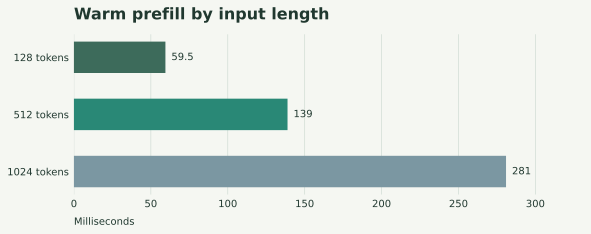

In [12]:
measurement_seconds = None if COURSE_SMOKE else perf_counter() - started_lab
quality = summarise_quality(quality_rows) if quality_rows else None

print("Profile summary:")
for row in profile_summary:
    print(row)
print("Translated request token counts:", language_rows)
if quality is not None:
    print("Strict quality:", quality)
    for condition in CONDITIONS:
        rows = [row for row in quality_rows if row["condition"] == condition]
        print("F-250 response:", next(row for row in rows if row["id"] == focus_case["id"]))
        failure = next((row for row in rows if not row["strict_pass"]), None)
        print("First strict failure:", failure)
    print("Measurement wall time, seconds:", measurement_seconds)
save("summary", {
    "mode": "formula_smoke" if COURSE_SMOKE else "cuda_profile",
    "cache_shape": cache_shape,
    "token_budget": GENERATED_TOKENS,
    "model_load_ms": load_ms,
    "measurement_wall_seconds": measurement_seconds,
    "first_profile": first_profile,
    "profiler": profile_summary,
    "translated_requests": language_rows,
    "quality": quality,
    "settings": {
        "model": MODEL_IDS["text"],
        "profile_repeats": REPEATS,
        "f250_case_id": focus_case["id"],
        "dossier_copies": DOSSIER_COPIES,
        "quality_batch": QUALITY_BATCH,
        "quality_token_budget": QUALITY_TOKEN_BUDGET,
        "quality_split": SPLIT_MANIFEST["dev"],
    },
})
save("records", {
    "profiles": measurements,
    "quality": quality_rows,
    "f250_prompts": {
        condition: answer_prompt(focus_case, records_for(focus_case, condition))
        for condition in CONDITIONS
    },
})

if COURSE_SMOKE:
    chart("Illustrative final KV allocation",
          [str(row["input_tokens"]) for row in profile_summary],
          [row["predicted_final_kv_bytes"] / 1024 for row in profile_summary], "KiB")
else:
    sweep = [row for row in profile_summary if row["experiment"] == "length"]
    chart("Warm prefill by input length", [row["condition"] for row in sweep],
          [row["median_prefill_ms"] for row in sweep], "Milliseconds")

Compare the shortest and longest warmed input. Cache bytes must grow
linearly with token positions for this cache configuration. Prefill and
aggregate allocator peaks also depend on kernels and temporary allocations.
Compare the translation rows as one matched example. A broader
language claim needs many translations and lengths. For a controlled
serving estimate, keep the model and output-token target fixed and add
concurrency in Lab 11.

[Return to the lesson](https://docs.recohut.com/courses/advanced-ai-systems-engineering/1-measure-the-model/02-profile-a-transformer).

[FlashAttention](https://arxiv.org/abs/2205.14135)
· [Hugging Face KV cache strategies](https://huggingface.co/docs/transformers/v4.51.3/en/kv_cache)

## Read the result

Inspect the per-case records in `evidence/` before drawing a conclusion from an aggregate. Use the printed sample size, split and hardware when comparing it with another run.

- [FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness](https://arxiv.org/abs/2205.14135)